<a href="https://colab.research.google.com/github/nguyenvanminh281005/bt4222-group12/blob/main/eda_sparsity_temporal_patterns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 2.3 — Sparsity & Temporal Patterns (MIND-small, temporal split)

**Purpose.** Reproduces the EDA figures in Section 2.2.4 of the interim report: user click-history sparsity (Fig. 8), article popularity concentration (Fig. 9), clicks by hour of day (Fig. 10) and time gaps between a user's consecutive impressions (Fig. 11).

**Inputs** (produced by the preprocessing notebook):
| File | Contents |
|---|---|
| `MIND_train_temporal.csv` | Days 1–4 impressions |
| `MIND_validation_temporal.csv` | Day 5 impressions |
| `MIND_test_temporal.csv` | Days 6–7 impressions |
| `MIND_news.csv` | News catalogue (train + dev `news.tsv`) |

**How to run on Google Colab**
1. Put the four CSVs in one Google Drive folder. The default in Step 0 is a shared drive at `Shareddrives/BT4222/data`.
2. Run **Step 0** and approve the Google Drive permission pop-up.
3. `Runtime → Run all`. A CPU runtime is enough; no GPU is needed for this notebook.

## Step 0 — Environment setup
Mounts Google Drive when running on Colab and sets `DATA_DIR`, the folder holding the input CSVs. Running locally, it reads from the current folder instead. The cell stops with a clear message if any input file is missing.

👉 **Edit `DATA_DIR`** if your files live in a different Drive folder.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Shortcut to the group's "Shared with me" folder, added to My Drive.
    # If the CSVs sit in a subfolder, add it to the end of this path.
    DATA_DIR = "/content/drive/MyDrive/BT4222 - Group 12"
else:
    DATA_DIR = "."                                    # local run: files next to the notebook

REQUIRED = ["MIND_train_temporal.csv", "MIND_validation_temporal.csv",
            "MIND_test_temporal.csv", "MIND_news.csv"]
missing = [f for f in REQUIRED if not os.path.exists(os.path.join(DATA_DIR, f))]
if missing:
    raise FileNotFoundError(f"Missing in {DATA_DIR}: {missing}\n"
                            f"Folder contents: {sorted(os.listdir(DATA_DIR)) if os.path.isdir(DATA_DIR) else 'folder not found'}")
print(f"Running on {'Colab' if IN_COLAB else 'local machine'} | all {len(REQUIRED)} input files found in {DATA_DIR}")

Mounted at /content/drive
Running on Colab | all 4 input files found in /content/drive/MyDrive/BT4222 - Group 12


## Step 1 — Load impressions and expand to exposure level
- Concatenates the three temporal splits into one behaviours table (`beh`, one row per impression) and checks the total is 230,117.
- Loads the news catalogue and **drops duplicate `news_id`s**: train and dev `news.tsv` overlap, so the raw concatenation has 93,698 rows but only 65,238 unique articles (the figure quoted in the report).
- Explodes each impression slate (`N12345-1 N67890-0 ...`) into one row per exposed article (`ex`), with `label = 1` for a click and `0` otherwise.
- Aggregates clicks and exposures per article (`item`), used for the popularity analysis.

In [2]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import os

cols = ["impression_id", "user_id", "time", "history", "impressions"]
splits = ["train", "validation", "test"]
beh = pd.concat([pd.read_csv(os.path.join(DATA_DIR, f"MIND_{s}_temporal.csv"), usecols=cols).assign(split=s)
                 for s in splits], ignore_index=True)
beh["time"] = pd.to_datetime(beh["time"], format="%Y-%m-%d %H:%M:%S")
beh["history"] = beh["history"].fillna("")
print(beh["split"].value_counts().reindex(splits).to_string())
assert len(beh) == 230_117, f"expected 230,117 impressions, got {len(beh):,}"
print(f"total impressions {len(beh):,}")

news_raw = pd.read_csv(os.path.join(DATA_DIR, "MIND_news.csv"))
news = news_raw.drop_duplicates("news_id").reset_index(drop=True)
print(f"news rows {len(news_raw):,} -> {len(news):,} unique articles after dropping duplicate news_id")

imp = beh["impressions"].str.split().explode()
ex = pd.DataFrame({"news_id": imp.str[:-2].values,
                   "label":   imp.str[-1].astype("int8").values})
item = ex.groupby("news_id")["label"].agg(clicks="sum", exposures="size")

N_USERS  = beh["user_id"].nunique()
N_ITEMS  = len(item)
N_CLICKS = int(item["clicks"].sum())
DENSITY  = N_CLICKS / (N_USERS * N_ITEMS) * 100
imp_per_user = beh.groupby("user_id").size()

print(f"users {N_USERS:,} | articles {N_ITEMS:,} | clicks {N_CLICKS:,}")
print(f"news catalogue {len(news):,} | exposed articles found in catalogue {item.index.isin(news['news_id']).mean()*100:.1f}%")


split
train         126695
validation     30270
test           73152
total impressions 230,117
news rows 93,698 -> 65,238 unique articles after dropping duplicate news_id
users 94,057 | articles 22,771 | clicks 347,727
news catalogue 65,238 | exposed articles found in catalogue 100.0%


## Step 2 — User sparsity: click-history length (report Fig. 8)
Each user's history length is the number of article IDs in their `history` field; we take the maximum across that user's impressions (history only grows over time). The histogram is clipped at 100 for readability, so the bar at 100 holds all users with ≥100 clicks.

**Why it matters:** 17.9% of users have fewer than 5 historical clicks and 2.3% have none, so user-ID embeddings would be learned from very little data. This motivates content- and time-based features that are shared across users.

count    94057.000000
mean        21.663778
std         27.783628
min          0.000000
25%          6.000000
50%         12.000000
75%         26.000000
max        558.000000
Name: hist_len, dtype: float64
0 history 2.26% | <5 17.91% | >100 2.36%


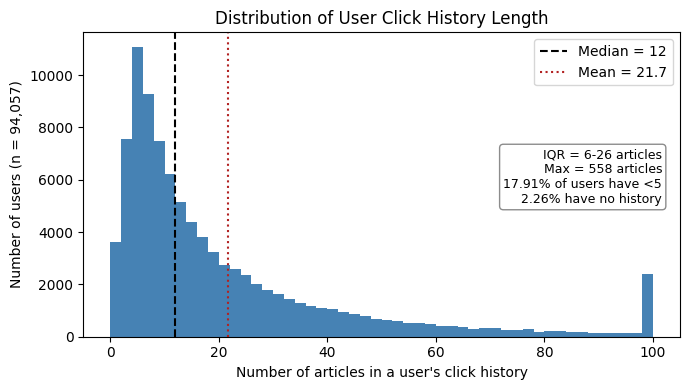

In [3]:
beh["hist_len"] = beh["history"].str.split().str.len().fillna(0).astype(int)
hist_len = beh.groupby("user_id")["hist_len"].max()

med, mean = hist_len.median(), hist_len.mean()
q1, q3 = hist_len.quantile(.25), hist_len.quantile(.75)
pct0, pct5 = (hist_len == 0).mean()*100, (hist_len < 5).mean()*100
XMAX = 100
print(hist_len.describe())
print(f"0 history {pct0:.2f}% | <5 {pct5:.2f}% | >100 {(hist_len>XMAX).mean()*100:.2f}%")

plt.figure(figsize=(7,4))
plt.hist(hist_len.clip(upper=XMAX), bins=np.arange(0, XMAX+2, 2), color="steelblue")
plt.axvline(med,  color="black",     ls="--", label=f"Median = {med:.0f}")
plt.axvline(mean, color="firebrick", ls=":",  label=f"Mean = {mean:.1f}")
plt.text(0.97, 0.62,
         f"IQR = {q1:.0f}-{q3:.0f} articles\n"
         f"Max = {hist_len.max():.0f} articles\n"
         f"{pct5:.2f}% of users have <5\n"
         f"{pct0:.2f}% have no history",
         transform=plt.gca().transAxes, ha="right", va="top", fontsize=9,
         bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=.9))
plt.xlabel("Number of articles in a user's click history")
plt.ylabel(f"Number of users (n = {N_USERS:,})")
plt.title("Distribution of User Click History Length")
plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

## Step 3 — Article popularity concentration (report Fig. 9)
Articles are ranked from most to least clicked, and the cumulative share of clicks is plotted against the share of articles. `share(f)` returns the share of all clicks captured by the top *f*% of articles.

**Why it matters:** 60% of exposed articles are never clicked and the top 1% take 54% of clicks, so a popularity baseline is strong but cannot rank fresh, unclicked articles. This motivates pairing `historical_ctr` with recency.

never clicked 60.0% | top1 54.3% top5 84.6% top20 98.3%


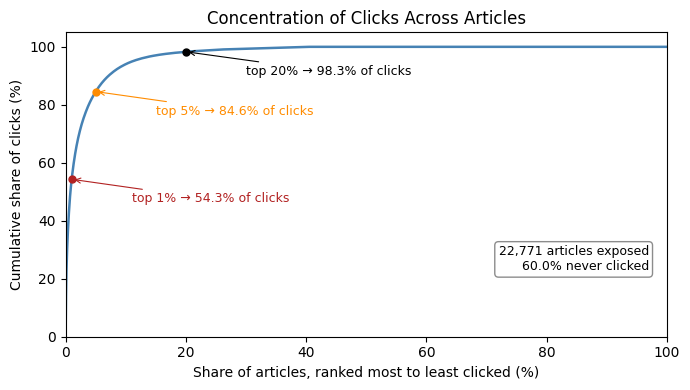

In [4]:
c = item["clicks"].sort_values(ascending=False).to_numpy()
x = np.arange(1, len(c)+1) / len(c) * 100
y = np.cumsum(c) / c.sum() * 100
def share(f):
    k = max(1, int(round(f/100 * len(c))))
    return c[:k].sum() / c.sum() * 100
zero = (c == 0).mean() * 100
print(f"never clicked {zero:.1f}% | top1 {share(1):.1f}% top5 {share(5):.1f}% top20 {share(20):.1f}%")

plt.figure(figsize=(7,4))
plt.plot(x, y, color="steelblue", lw=1.8)
for f, col in [(1, "firebrick"), (5, "darkorange"), (20, "black")]:
    s = share(f)
    plt.plot([f], [s], "o", color=col, ms=5)
    plt.annotate(f"top {f}% → {s:.1f}% of clicks", xy=(f, s), xytext=(f+10, s-8),
                 fontsize=9, color=col,
                 arrowprops=dict(arrowstyle="->", color=col, lw=.8))
plt.text(0.97, 0.30,
         f"{len(c):,} articles exposed\n{zero:.1f}% never clicked",
         transform=plt.gca().transAxes, ha="right", va="top", fontsize=9,
         bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=.9))
plt.xlim(0, 100); plt.ylim(0, 105)
plt.xlabel("Share of articles, ranked most to least clicked (%)")
plt.ylabel("Cumulative share of clicks (%)")
plt.title("Concentration of Clicks Across Articles")
plt.tight_layout(); plt.show()

## Step 4 — Time gaps between a user's consecutive impressions (report Fig. 11)
Impressions are sorted by user and time; the gap is the difference between consecutive timestamps for the same user (each user's first impression has no gap and is dropped, as are zero gaps). The histogram covers 0–72 h, with reference lines at 24 h and 48 h.

**Why it matters:** the distribution is multi-modal (same-session returns, then bumps at ~24 h and ~48 h), so the median of 7.2 h is not a typical gap. This motivates binning `inactivity_gap` rather than using a single average.

gaps 136,038 | median 7.2 h | <30min 11.3% | 20-28h 16.3% | 44-52h 5.3% | >72h 3.1%
window: 2019-11-09 00:00:19 to 2019-11-15 23:58:03


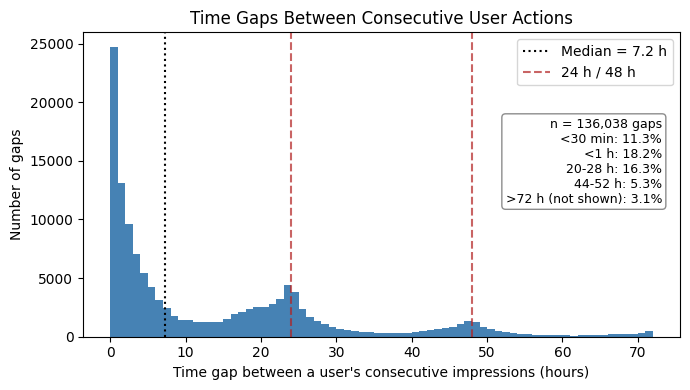

In [5]:
g = beh.sort_values(["user_id","time"]).groupby("user_id")["time"].diff().dt.total_seconds() / 60
g = g.dropna(); g = g[g > 0]
gh = g / 60

def band(a, b): return ((gh >= a) & (gh <= b)).mean() * 100
p1, p24, p48 = (gh < 1).mean()*100, band(20, 28), band(44, 52)
beyond = (gh > 72).mean() * 100
print(f"gaps {len(gh):,} | median {gh.median():.1f} h | <30min {(gh<0.5).mean()*100:.1f}% "
      f"| 20-28h {p24:.1f}% | 44-52h {p48:.1f}% | >72h {beyond:.1f}%")
print(f"window: {beh.time.min()} to {beh.time.max()}")

plt.figure(figsize=(7,4))
plt.hist(gh[gh <= 72], bins=72, color="steelblue")
for h in (24, 48):
    plt.axvline(h, color="firebrick", ls="--", alpha=.7)
plt.axvline(gh.median(), color="black", ls=":", label=f"Median = {gh.median():.1f} h")
plt.plot([], [], color="firebrick", ls="--", alpha=.7, label="24 h / 48 h")
plt.text(0.97, 0.72,
         f"n = {len(gh):,} gaps\n"
         f"<30 min: {(gh<0.5).mean()*100:.1f}%\n"
         f"<1 h: {p1:.1f}%\n"
         f"20-28 h: {p24:.1f}%\n"
         f"44-52 h: {p48:.1f}%\n"
         f">72 h (not shown): {beyond:.1f}%",
         transform=plt.gca().transAxes, ha="right", va="top", fontsize=9,
         bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=.9))
plt.xlabel("Time gap between a user's consecutive impressions (hours)")
plt.ylabel("Number of gaps")
plt.title("Time Gaps Between Consecutive User Actions")
plt.legend(loc="upper right"); plt.tight_layout(); plt.show()

## Step 5 — Clicks by hour of day (report Fig. 10)
Each exposure inherits the hour of its impression (`repeat` by slate length keeps rows aligned with `ex`, checked by the `assert`), then clicks are summed per hour.

**Why it matters:** clicks peak at 08:00 and are lowest around 23:00, so the value of a Spotlight slot depends on when it is filled. This supports `session_hour` as a feature and time-window based slate rotation.

hour
0      2364
1      2772
2      4312
3      7574
4     13177
5     20966
6     25904
7     27182
8     29277
9     25962
10    28097
11    28210
12    26160
13    23547
14    18461
15    14000
16    11689
17     9290
18     7750
19     6253
20     5202
21     4230
22     3108
23     2240
Name: label, dtype: int64
peak 08:00 (29,277) | quietest 23:00 (2,240) 


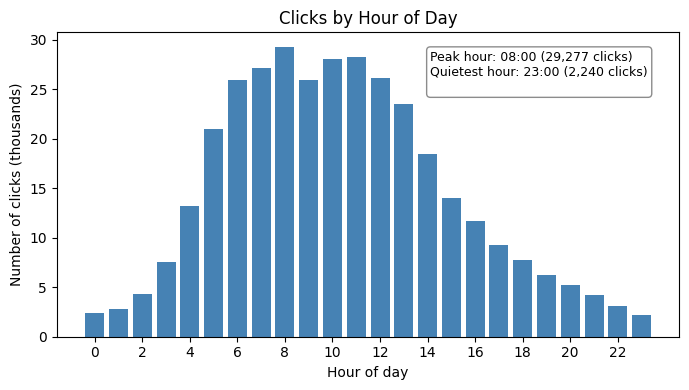

In [6]:
slate_len = beh["impressions"].str.split().str.len()
hr = pd.DataFrame({"hour":  beh["time"].dt.hour.repeat(slate_len).values,
                   "label": ex["label"].values})
assert len(hr) == len(ex)
hourly = hr.groupby("hour")["label"].sum()

peak, low = hourly.idxmax(), hourly.idxmin()

print(hourly)
print(f"peak {peak:02d}:00 ({hourly.max():,}) | quietest {low:02d}:00 ({hourly.min():,}) ")

plt.figure(figsize=(7,4))
plt.bar(hourly.index, hourly/1000, color="steelblue")
plt.xticks(range(0, 24, 2))
plt.text(0.60, 0.94,
         f"Peak hour: {peak:02d}:00 ({hourly.max():,} clicks)\n"
         f"Quietest hour: {low:02d}:00 ({hourly.min():,} clicks)\n",
         transform=plt.gca().transAxes, ha="left", va="top", fontsize=9,
         bbox=dict(boxstyle="round", fc="white", ec="grey", alpha=.9))
plt.xlabel("Hour of day")
plt.ylabel("Number of clicks (thousands)")
plt.title("Clicks by Hour of Day")
plt.tight_layout(); plt.show()